# Session 5 — Temporal EDA
### FAA National Wildlife Strike Database

The first notebook in this project to read from `data/processed/strikes_clean.pkl.gz` instead of
`Public.csv` — worth confirming that's actually true below, not just asserting it.

**Scope: when strikes happen, nothing else.** Two questions, chosen because they exercise the two biggest
constraints the first four sessions established:

1. **Seasonality across the full span (1990-2025).** Has to be measured as each month's *share* of its
   own year's total, not a raw count — raw counts would just re-trace the 10x reporting-volume growth
   session 1 already found, burying any real seasonal shape under it.
2. **Hour-of-day, restricted to 2020-2023.** Session 3 established that `TIME` is genuinely reliable
   (~87-93% filled) only in this four-year window — before it, patchy; after it, collapsed again to
   ~55-59%. Widening this window for "more data" would reproduce the exact mistake that produced session
   1's wrong `TIME` conclusion in the first place.

Nothing here touches species, damage, phase of flight, or geography — those are later sessions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 40)
pd.set_option('display.width', 140)

df = pd.read_pickle('../data/processed/strikes_clean.pkl.gz')
print('shape:', df.shape)
print('NUM_SEEN dtype:', df['NUM_SEEN'].dtype, '(confirms this is the cleaned file, not the raw CSV --')
print('a fresh read_csv of Public.csv would show plain strings here, not an ordered category)')


shape: (354144, 101)
NUM_SEEN dtype: category (confirms this is the cleaned file, not the raw CSV --
a fresh read_csv of Public.csv would show plain strings here, not an ordered category)


## 1. Seasonality, full span

`INCIDENT_MONTH` first: confirming it's trustworthy before building anything on it.

In [2]:
print('INCIDENT_MONTH nulls:', df['INCIDENT_MONTH'].isna().sum())
parsed = pd.to_datetime(df['INCIDENT_DATE'])
print('INCIDENT_MONTH matches the month in INCIDENT_DATE for every row:',
      (parsed.dt.month == df['INCIDENT_MONTH']).all())
print('INCIDENT_YEAR matches too:', (parsed.dt.year == df['INCIDENT_YEAR']).all())
print()
print('latest INCIDENT_DATE in the dataset:', parsed.max().date())


INCIDENT_MONTH nulls: 0
INCIDENT_MONTH matches the month in INCIDENT_DATE for every row: True
INCIDENT_YEAR matches too: True

latest INCIDENT_DATE in the dataset: 2026-08-24


`INCIDENT_MONTH` is fully populated and agrees with `INCIDENT_DATE` on every row — safe to build on
directly, no parsing needed.

**2026 is excluded from the seasonality analysis below, and not just because the calendar year isn't
over.** The latest date in the dataset is August 24, 2026, and August itself is already suppressed —
2026's August has 18 rows against 1,825-3,221 in August of each of the six years before it. That's
reporting lag actively shrinking the most recent month, not a real drop in strikes, consistent with what
session 1 already flagged about recent-year reporting lag in general. A partial year with its last visible
month itself heavily undercounted would distort a share-within-year calculation far more than it would
help; 1990-2025 is the full, comparable span.

In [3]:
full_years = df[df['INCIDENT_YEAR'] <= 2025]
month_counts = full_years.groupby(['INCIDENT_YEAR', 'INCIDENT_MONTH']).size().unstack(fill_value=0)
month_share = month_counts.div(month_counts.sum(axis=1), axis=0) * 100

summary = pd.DataFrame({
    'median_pct': month_share.median(),
    'p25': month_share.quantile(0.25),
    'p75': month_share.quantile(0.75),
}).round(2)
print(summary)
print()
print('sum of medians (sanity check, should be close to 100):', round(summary['median_pct'].sum(), 1))


                median_pct    p25    p75
INCIDENT_MONTH                          
1                     3.49   2.86   3.99
2                     3.16   2.81   3.60
3                     4.83   4.46   5.62
4                     7.04   6.52   7.48
5                     9.72   8.92  10.18
6                     8.23   7.69   8.72
7                    12.46  10.59  13.20
8                    13.80  13.33  14.25
9                    13.26  13.10  14.01
10                   12.79  12.19  13.27
11                    6.94   6.60   7.90
12                    4.03   3.72   4.84

sum of medians (sanity check, should be close to 100): 99.8


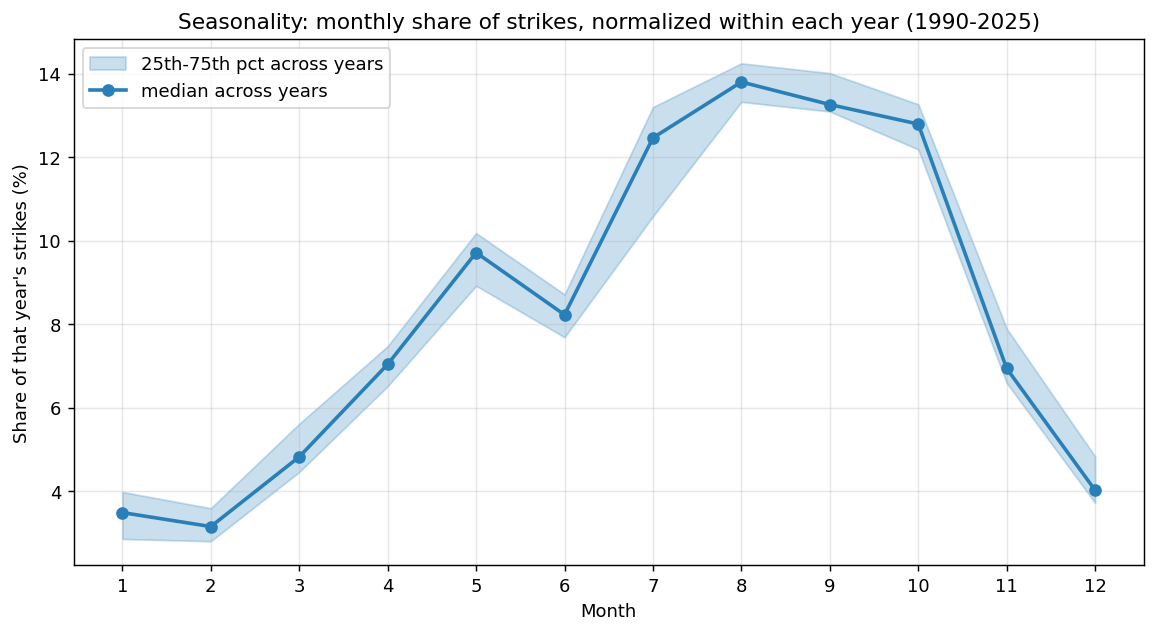

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
median = month_share.median()
p25 = month_share.quantile(0.25)
p75 = month_share.quantile(0.75)
months = range(1, 13)
ax.fill_between(months, p25, p75, alpha=0.25, color='#2980b9', label='25th-75th pct across years')
ax.plot(months, median, marker='o', color='#2980b9', linewidth=2, label='median across years')
ax.set_xticks(months)
ax.set_xlabel('Month')
ax.set_ylabel("Share of that year's strikes (%)")
ax.set_title('Seasonality: monthly share of strikes, normalized within each year (1990-2025)')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()


A clear, single-season shape: a trough in January-February (~3.2-3.5%), a climb through spring, and
a sustained peak across July-October (12.5-13.8% each — together, four months carry roughly half the
year's strikes), before falling back through November-December. Worth naming two specific features rather
than just "there's a peak":

- **A local peak in May (9.7%) followed by a dip in June (8.2%)** before the main July-October plateau —
  not a smooth monotonic rise. The IQR band is tight around June specifically, so this isn't one unusual
  year's noise.
- **August is the single highest month**, not July or September, though all four mid-peak months are
  close enough that calling out one as "the" peak month would overstate the precision of a four-month-wide
  plateau.

A migratory/breeding-season bird-activity hypothesis fits this shape, and is worth naming as a plausible
outside-knowledge explanation — but this dataset alone shows a pattern, not a cause, and doesn't
distinguish that hypothesis from, say, a seasonal change in flight volume. Not pursued further here.

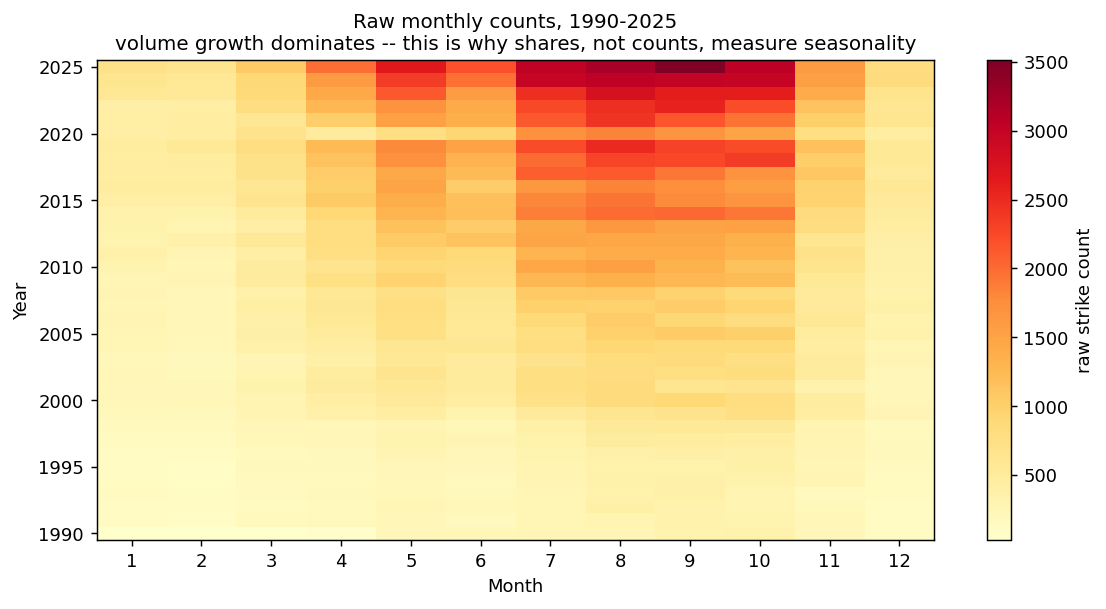

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
raw = month_counts
im = ax.imshow(raw.values, aspect='auto', cmap='YlOrRd', origin='lower')
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(0, len(raw.index), 5))
ax.set_yticklabels(raw.index[::5])
ax.set_xlabel('Month')
ax.set_ylabel('Year')
ax.set_title('Raw monthly counts, 1990-2025\nvolume growth dominates -- this is why shares, not counts, measure seasonality',
             fontsize=11)
fig.colorbar(im, ax=ax, label='raw strike count')
fig.tight_layout()


Shown for context, not as the seasonality answer — the dominant visual pattern here is the
year-over-year volume increase (pale at the bottom, dark at the top) that session 1 already established,
with the seasonal columns only faintly visible underneath it. This is exactly what normalizing by year was
for: the chart above it isolates the shape this one buries.

In [6]:
early = month_share.loc[1990:1999].mean()
recent = month_share.loc[2016:2025].mean()
compare = pd.DataFrame({
    'early_1990s_pct': early,
    'recent_2016_2025_pct': recent,
    'diff': recent - early,
}).round(2)
print(compare)


                early_1990s_pct  recent_2016_2025_pct  diff
INCIDENT_MONTH                                             
1                          4.14                  2.92 -1.22
2                          3.64                  2.97 -0.67
3                          5.56                  4.48 -1.08
4                          6.30                  6.94  0.64
5                          8.82                 10.02  1.20
6                          7.44                  8.37  0.94
7                         10.36                 13.12  2.76
8                         13.05                 14.30  1.25
9                         13.63                 13.73  0.10
10                        13.19                 12.75 -0.43
11                         8.61                  6.80 -1.81
12                         5.27                  3.60 -1.68


The shape is broadly stable across the 36-year span — same trough months, same peak months — but not
perfectly static. The summer peak has sharpened: July rose from 10.36% to 13.12% of the year (+2.76
points), while every winter month (January, November, December) declined by 1.2-1.8 points. Worth stating
plainly without forcing an explanation: this could reflect a genuine shift in when strikes occur, or it
could reflect early-1990s reporting being noisier/less consistent in a way that partially smooths out a
seasonal signal that was always this sharp — this dataset doesn't distinguish between those on its own.

## 2. Hour-of-day, 2020-2023 only

Restricted to the one four-year window session 3 established as genuinely reliable for `TIME` — not
extended for more data, which is exactly the instinct that produced session 1's original, wrong `TIME`
conclusion.

`TIME` is confirmed local time at the airport, per FAA's own reporting instructions — not UTC/Zulu — so an
hour value here is directly meaningful without a timezone adjustment. Checked as a real question, not
assumed, even though it resolved cleanly.

In [7]:
window = df[df['INCIDENT_YEAR'].between(2020, 2023)].copy()
print('rows in the 2020-2023 window:', len(window))
print(f"TIME filled: {window['TIME'].notna().sum()} ({window['TIME'].notna().mean()*100:.1f}%)")
print()

hour = pd.to_datetime(window['TIME'], format='%H:%M', errors='coerce').dt.hour
n_parse_fail = (window['TIME'].notna() & hour.isna()).sum()
print('rows where TIME was filled but failed to parse as HH:MM:', n_parse_fail)
print('hour successfully extracted:', hour.notna().sum())


rows in the 2020-2023 window: 64116
TIME filled: 57579 (89.8%)

rows where TIME was filled but failed to parse as HH:MM: 0
hour successfully extracted: 57579


Zero parse failures — every non-null `TIME` value in this window is a clean `"HH:MM"` string, so the
`57,579` rows behind the chart below are exactly the `89.8%` of the window where `TIME` is filled, no
silent shrinkage from `errors='coerce'` to report.

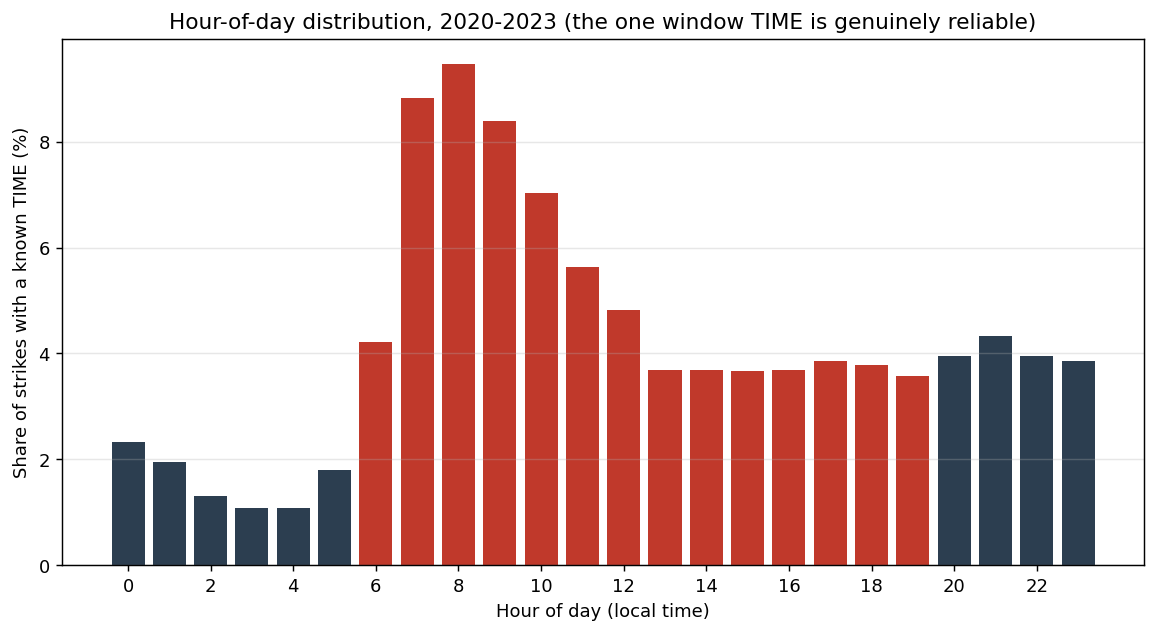

In [8]:
hour_counts = hour.value_counts().sort_index()
hour_share = hour_counts / hour_counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#c0392b' if 6 <= h < 20 else '#2c3e50' for h in hour_share.index]
ax.bar(hour_share.index, hour_share.values, color=colors)
ax.set_xlabel('Hour of day (local time)')
ax.set_ylabel('Share of strikes with a known TIME (%)')
ax.set_title('Hour-of-day distribution, 2020-2023 (the one window TIME is genuinely reliable)')
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3, axis='y')
fig.tight_layout()


One clear peak, not two: strikes climb sharply from a pre-dawn low (1.1-1.3% at 3-5am) to the day's
single highest hour at 08:00 (9.4%), then decline steadily through the afternoon and evening, bottoming
out again overnight. There's a secondary feature worth naming precisely: hours 20-23 sit at a modestly
*elevated* floor (3.6-4.3%) compared to the true overnight trough at 3-5am (1.1-1.3%) — not a second peak,
but not a flat tail either.

Two plausible explanations for the dominant morning peak, both consistent with a single dataset like this
one and not distinguishable from it alone: dawn bird activity (foraging, dawn chorus movement) and morning
air-traffic volume (a genuine peak in flights, not just strikes) would produce the same shape. Worth
flagging as the obvious next question — is this a strike-*rate* peak or a flight-*volume* peak? — rather
than answering it here without the traffic-volume data this dataset doesn't contain.

## 3. Cross-checking `TIME` against `TIME_OF_DAY`

Validation, not a new analysis: do the two independently-recorded time fields roughly agree, on the
2020-2023 rows where both are present? The bucket boundaries below (06-09, 09-18, 18-21, 21-06) are a
convenience grouping of the derived hour for this comparison, not an FAA-defined standard — `TIME_OF_DAY`
itself is assigned by observer judgment relative to actual sunrise/sunset, which don't fall on fixed clock
hours, so a blurry edge at dawn and dusk is the expected, correct outcome here, not a problem to solve.

In [9]:
both = window['TIME_OF_DAY'].notna() & hour.notna()
print('rows with both TIME and TIME_OF_DAY present:', both.sum())
print('TIME_OF_DAY categories:', sorted(window['TIME_OF_DAY'].dropna().unique()))
print()

def bucket(h):
    if 6 <= h < 9:
        return '06-09 (dawn-ish)'
    if 9 <= h < 18:
        return '09-18 (day-ish)'
    if 18 <= h < 21:
        return '18-21 (dusk-ish)'
    return '21-06 (night-ish)'

hour_bucket = hour[both].apply(bucket)
tod = window.loc[both, 'TIME_OF_DAY']
ct = (pd.crosstab(hour_bucket, tod, normalize='index') * 100).round(1)
print(ct)
print()
print('rows per bucket:', hour_bucket.value_counts().to_dict())


rows with both TIME and TIME_OF_DAY present: 29751
TIME_OF_DAY categories: ['Dawn', 'Day', 'Dusk', 'Night']

TIME_OF_DAY        Dawn   Day  Dusk  Night
TIME                                      
06-09 (dawn-ish)   16.4  79.6   1.1    2.9
09-18 (day-ish)     0.2  94.0   2.1    3.7
18-21 (dusk-ish)    0.1  34.7  20.6   44.7
21-06 (night-ish)   2.7   4.4   1.1   91.8

rows per bucket: {'09-18 (day-ish)': 13518, '21-06 (night-ish)': 7187, '06-09 (dawn-ish)': 4604, '18-21 (dusk-ish)': 4442}


Exactly the pattern expected from two fields measuring the same thing by different methods — clean
agreement where there's no real ambiguity, blurry agreement where there is:

- **Midday and overnight are clean.** 09-18 is labeled `Day` 94.0% of the time; 21-06 is labeled `Night`
  91.8% of the time. Minimal three-way splitting in either.
- **Dawn is blurry, as expected.** 06-09 splits 79.6% `Day` / 16.4% `Dawn` — sunrise doesn't happen at a
  fixed clock hour across seasons and latitudes, so some mornings in this bucket are still dark and some
  are already full daylight by the time `TIME_OF_DAY` was assigned.
- **Dusk is considerably blurrier than dawn, and that asymmetry is itself worth noting.** 18-21 splits
  three ways — 34.7% `Day`, 20.6% `Dusk`, 44.7% `Night` — far more even than dawn's split. A plausible
  reason: evening daylight length varies more across the seasons than morning daylight does at the
  latitudes most of this dataset's airports sit at, so 6-9pm genuinely spans the full range from
  midsummer daylight to midwinter darkness, while 6-9am varies less. Offered as a hypothesis consistent
  with the pattern, not a conclusion this dataset proves on its own.

A clean match everywhere would have been the actually suspicious result, given `TIME_OF_DAY` is observer
judgment rather than a clock rule — this is what a correct validation looks like, not a failed one.

## Summary

**Seasonality (1990-2025, share-of-year):** a single broad season, not scattered noise — trough in
January-February (~3.2-3.5%), climb through spring with a local May peak and a real June dip, sustained
peak across July-October (four months carrying roughly half the year's strikes, August highest at 13.8%),
decline through November-December. The shape is stable across the full span but not static: the summer
peak has sharpened and winter's share has declined modestly from the 1990s to the 2016-2025 decade.

**Hour-of-day (2020-2023 only):** one clear peak at 08:00 (9.4%), climbing sharply from a 3-5am trough
(1.1-1.3%) and declining gradually through the rest of the day, with a modestly elevated evening floor
(20-23h) rather than a true second peak. Whether this reflects strike *risk* or flight *volume* timing
isn't answerable from this dataset alone.

**`TIME` vs. `TIME_OF_DAY`:** validates cleanly — agreement is tight at midday and overnight, blurry at
dawn and dusk (as it should be, since both are genuinely gradual transitions rather than clock events),
and dusk is measurably blurrier than dawn, plausibly reflecting more seasonal variation in evening daylight
length than morning daylight length at this dataset's latitudes.

**Next:** species, size, and damage distributions — does the same volume-vs-share discipline established
here and in session 1 carry over to a categorical dimension, or does it need its own approach.